<font size=15 color="orange">Tarea 5: Estimación de Parámetros</b></font>

Diego Marquez Franco


In [1]:
import numpy as np

# 1. Generación de datos observados

In [5]:
r_real = 0.9
K_real = 30.0
sigma = 0.5
np.random.seed(42)

t0, tf, h = 0, 10, 0.1
t = np.arange(t0, tf + h, h)
y0 = np.array([1.0])  

def f_logistico(t, u, r=r_real, K=K_real):
    return r * u * (1 - u / K)

def euler_implicito_numerico(f, t0, tf, y0, h, tol_newton, max_iter_newton, delta):
    tspan = np.arange(t0, tf + h, h)
    ysol = np.zeros((len(tspan), len(y0)))
    ysol[0] = y0
    for k in range(len(tspan) - 1):
        tk1 = tspan[k+1]
        yk = ysol[k]
        y_next = yk.copy()
        for i in range(max_iter_newton):
            F = y_next - yk - h * f(tk1, y_next)
            n = len(y0)
            Jf_num = np.zeros((n, n))
            for j in range(n):
                e_j = np.zeros(n)
                e_j[j] = 1.0
                Jf_num[:, j] = (f(tk1, y_next + delta*e_j) - f(tk1, y_next)) / delta
            J = np.eye(n) - h * Jf_num
            delta_y = np.linalg.solve(J, -F)
            y_next = y_next + delta_y
            if np.linalg.norm(delta_y) < tol_newton:
                break
        ysol[k+1] = y_next
    return tspan, ysol

_, u_real = euler_implicito_numerico(
    lambda t, u: f_logistico(t, u, r_real, K_real), 
    t0, tf, y0, h, 1e-10, 50, 1e-6)

ruido = np.random.normal(0, sigma, size=u_real.shape)
u_obs = u_real.flatten() + ruido


# 2. Implementación de las funciones del gradiente

In [6]:

import numpy as np


def f_extendido(t, Y, r, K):
    
    u, v, w = Y
    f1 = r * u * (1 - u / K)
    f2 = r * v * (1 - 2*u / K) + u * (1 - u / K)
    f3 = r * w * (1 - 2*u / K) + r * (u**2) / (K**2)
    return np.array([f1, f2, f3])


def resolver_extendido(r, K, t, h=0.1):
    Y0 = np.array([1.0, 0.0, 0.0])
    
    def f(tk, Yk):
        return f_extendido(tk, Yk, r, K)
    
    _, Ysol = euler_implicito_numerico(f, t[0], t[-1], Y0, h, 1e-10, 50, 1e-6)
    
    u = Ysol[:, 0]
    v = Ysol[:, 1]
    w = Ysol[:, 2]
    return u, v, w



def calcular_gradiente(r, K, u_obs, t, h=0.1):
    u, v, w = resolver_extendido(r, K, t, h)
    
    diff = u_obs - u

    dS_dr = -np.sum(diff * v)
    dS_dK = -np.sum(diff * w)
    
    return np.array([dS_dr, dS_dK])


# 3. Evaluación y Almacenamiento.

In [7]:
r_vals = np.linspace(0.5, 1.3, 15)   
K_vals = np.linspace(20, 40, 15)     #

R, K = np.meshgrid(r_vals, K_vals)

Grad_r = np.zeros_like(R)
Grad_K = np.zeros_like(K)

for i in range(R.shape[0]):
    for j in range(R.shape[1]):
        grad = calcular_gradiente(R[i, j], K[i, j], u_obs, t)
        Grad_r[i, j] = grad[0]   # ∂S/∂r
        Grad_K[i, j] = grad[1]   # ∂S/∂K


print(f"Evaluación del gradiente completada y almacenada {Grad_r}, {Grad_K}")


Evaluación del gradiente completada y almacenada [[-2.55660103e+06 -2.01817193e+06 -1.55997677e+06 -1.18638110e+06
  -8.88668889e+05 -6.54431310e+05 -4.71498748e+05 -3.29300416e+05
  -2.19137947e+05 -1.34046069e+05 -6.85271209e+04 -1.82747867e+04
   2.00713348e+04  4.91295491e+04  7.09396808e+04]
 [-2.67000324e+06 -2.09824395e+06 -1.61210185e+06 -1.21634907e+06
  -9.01471523e+05 -6.54091289e+05 -4.61194983e+05 -3.11534047e+05
  -1.95874959e+05 -1.06829643e+05 -3.85651896e+04  1.34911425e+04
   5.29115449e+04  8.24824749e+04  1.04376960e+05]
 [-2.76656422e+06 -2.16147995e+06 -1.64824793e+06 -1.23165359e+06
  -9.01053449e+05 -6.41910345e+05 -4.40285999e+05 -2.84234976e+05
  -1.63998376e+05 -7.17855477e+04 -1.45015185e+03  5.18272218e+04
   9.18139810e+04  1.21451334e+05  1.43034864e+05]
 [-2.84640799e+06 -2.20765722e+06 -1.66799232e+06 -1.23179244e+06
  -8.86907273e+05 -6.17413552e+05 -4.08344392e+05 -2.47026287e+05
  -1.23179005e+05 -2.86272642e+04  4.30674277e+04  9.69511421e+04
   1.3

In [8]:
print("∇S en (r=0.9, K=30):", 
      calcular_gradiente(0.9, 30, u_obs, t))
print("Magnitud media del gradiente:", 
      np.mean(np.sqrt(Grad_r**2 + Grad_K**2)))


∇S en (r=0.9, K=30): [7351.63654757  312.07575253]
Magnitud media del gradiente: 790702.6605912426


# 4. Visualización del campo de gradiente

In [9]:
import matplotlib.pyplot as plt

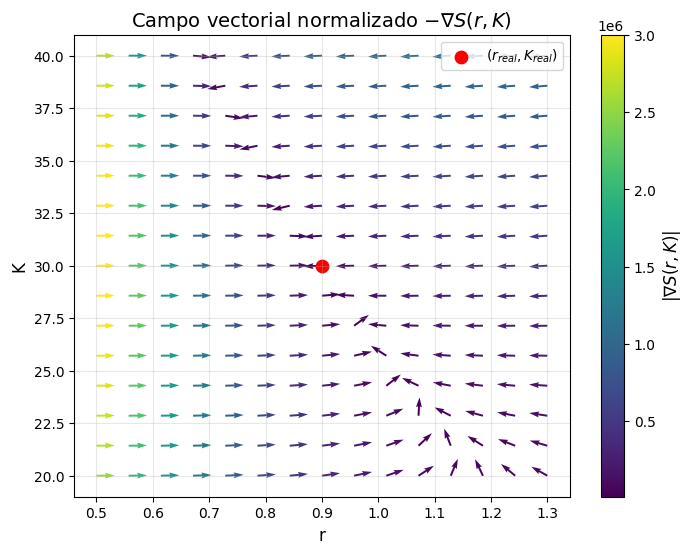

In [10]:

magnitud = np.sqrt(Grad_r**2 + Grad_K**2)

Ur = -Grad_r / (magnitud + 1e-12)
Uk = -Grad_K / (magnitud + 1e-12)

plt.figure(figsize=(8,6))
plt.quiver(R, K, Ur, Uk, magnitud, cmap='viridis')

cbar = plt.colorbar()
cbar.set_label(r"$|\nabla S(r,K)|$", fontsize=12)

plt.scatter(r_real, K_real, color='red', s=80, label='$(r_{real}, K_{real})$')
plt.xlabel("r", fontsize=12)
plt.ylabel("K", fontsize=12)
plt.title("Campo vectorial normalizado $-\\nabla S(r,K)$", fontsize=14)
plt.legend()
plt.grid(alpha=0.3)
plt.show()
